# 23CSE353 - Data Visualization Case Study
## MED-04: Symptoms to Disease: Understanding Patterns in Medical Records
### *From Data to Decision: Deciphering Clinical Complexity, Diagnostic Overlap, and Dataset Imbalance*

---

* **Author:** Data Analytics & Visualization Team
* **Topic Code:** MED-04 (Medical Records & Clinical Informatics)
* **Dataset:** Disease Prediction Based on Symptoms (Kaggle / Curated Benchmark)
* **Primary Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn), Tableau Desktop/Public, LaTeX
* **Submission Deadline:** 15 October 2026

---

## 1. Executive Summary & Action-Target-Purpose (ATP) Framework

### 1.1 Clinical Scenario
A health analytics department is evaluating electronic health record (EHR) symptom patterns to modernize outpatient triage protocols and clinical intake questionnaires. The challenge lies in untangling which symptoms provide high diagnostic discrimination, which symptoms are ubiquitous "chameleons" shared across dozens of diseases, where clinical confusion risks exist due to overlapping symptom profiles, and how synthetic dataset imbalances distort machine learning assumptions.

**Core Mandate:** *Communicate patterns clearly to support operational and triage decisions, NOT to make automated medical diagnoses.*

### 1.2 The Action-Target-Purpose (ATP) Matrix

| Dimension | Specification | Strategic Rationale |
| :--- | :--- | :--- |
| **ACTION** | **What action/decision should this analysis support?** | 1. Optimize triage intake questionnaires from 131 exhaustive queries down to dynamic, branching workflows.<br>2. Establish mandatory laboratory reflex protocols for high-overlap disease pairs.<br>3. Correct synthetic data sampling biases prior to deploying diagnostic AI. |
| **TARGET** | **Who is the audience / decision-maker?** | **Health Analytics Director, Clinical Informatics Operations Committee, and Triage Protocol Leads.** |
| **PURPOSE** | **Why does this decision matter?** | 1. **Projected Latency Reduction & Survey Relief:** Targets an estimated ~60% reduction in average triage questionnaire duration by replacing exhaustive screening with dynamic branching.<br>2. **Mitigates Diagnostic Error:** Flags near-identical conditions (e.g., Viral Hepatitis variants or Malaria vs. Typhoid) that cannot be safely separated by symptoms alone.<br>3. **Prevents Catastrophic Model Failure:** Avoids deploying models that rely on artificial class balance and zero-variance data artifacts. |

---

## 2. Environment Setup & Visual Configuration

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, leaves_list

warnings.filterwarnings('ignore')

# Set aesthetic visualization standards
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'

print("Environment configured successfully!")

Environment configured successfully!


## 3. Exploratory Data Analysis (EDA) & Forensic Data Profiling

Before creating visualizations, we conduct an exhaustive audit of the raw dataset:
1. **Dimensions & Data Types:** Checking feature structures and encoding.
2. **Missingness & Empty Columns:** Identifying ghost columns created by delimiter inconsistencies.
3. **Zero-Variance Features:** Identifying dead or uninformative symptoms.
4. **Header Inconsistencies:** Detecting whitespace irregularities and duplicate names.
5. **Class Balance:** Auditing disease frequency distribution.

In [2]:
# Ingest raw dataset
raw_candidates = ['data/train_disease.csv', 'data/Training.csv', 'data/Training_raw.csv', 'data/train.csv', 'Training.csv']
raw_path = next((p for p in raw_candidates if os.path.exists(p)), None)
if raw_path is None:
    raw_path = [os.path.join('data', f) for f in os.listdir('data') if f.endswith('.csv') and 'long' not in f.lower()][0]
print(f"Loading raw dataset from: {raw_path}")
raw_df = pd.read_csv(raw_path)
print(f"Raw Dataset Shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")

# Inspect null values
null_counts = raw_df.isnull().sum()
cols_with_nulls = null_counts[null_counts > 0]
print(f"\nColumns containing missing values:")
print(cols_with_nulls)

# Inspect disease class balance
disease_counts = raw_df['prognosis'].value_counts()
print(f"\nTotal Unique Diseases: {raw_df['prognosis'].nunique()}")
print(f"Record count per disease (min, max): ({disease_counts.min()}, {disease_counts.max()})")

Loading raw dataset from: data/train_disease.csv
Raw Dataset Shape: 4920 rows x 134 columns

Columns containing missing values:
Unnamed: 133    4920
dtype: int64

Total Unique Diseases: 41
Record count per disease (min, max): (120, 120)


### 3.1 Forensic EDA Key Findings:
1. **Ghost Column:** `Unnamed: 133` contains 100% missing values (4,920 NaNs), generated by a trailing comma in the source CSV.
2. **Duplicate Symptom Header Bug:** The dataset contained two columns for `fluid_overload`:
   - `fluid_overload` has exactly 0 occurrences (zero-variance dead feature).
   - `fluid_overload.1` has 114 occurrences (all tied to *Alcoholic Hepatitis*).
3. **Artificial Class Balance:** Each of the 41 diseases contains exactly 120 records ($41 	imes 120 = 4,920$). This is an artificial synthetic balance.
4. **Permutation Redundancy:** Despite having 120 rows per disease, there are only between 5 and 10 unique symptom patterns per disease, repeated 12 to 24 times.
5. **Typographical & Whitespace Inconsistencies:** Multiple disease names and symptom headers have typos (e.g., `'Peptic ulcer diseae'`, `'Diabetes '`, `'spotting_ urination'`).

## 4. Data Cleaning, Standardization & Clinical Domain Mapping

We apply rigorous cleaning:
- Drop `Unnamed: 133` and the dead zero-variance `fluid_overload` column.
- Rename `fluid_overload.1` to `fluid_overload`.
- Standardize all column names (snake_case, trim whitespace).
- Correct disease typos and trailing whitespace.
- Categorize diseases into 6 high-level **Clinical Specialty Domains** (Hospital Departments).
- Calculate row-level patient `symptom_count` (symptom burden).

In [3]:
# 1. Load cleaned training data from our pipeline
df = pd.read_csv('data/Training_Cleaned.csv')
print(f"Cleaned Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")

# Identify symptom columns
symptom_cols = [c for c in df.columns if c not in ['patient_id', 'prognosis', 'clinical_domain', 'symptom_count']]
print(f"Active Symptom Features: {len(symptom_cols)}")

# Display sample of patient records
df[['patient_id', 'prognosis', 'clinical_domain', 'symptom_count'] + symptom_cols[:5]].head(5)

Cleaned Dataset Dimensions: 4920 rows x 135 columns
Active Symptom Features: 131


,patient_id,prognosis,clinical_domain,symptom_count,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering
0,PAT_0001,Fungal infection,Dermatology & Allergy,4,1,1,1,0,0
1,PAT_0002,Fungal infection,Dermatology & Allergy,3,0,1,1,0,0
2,PAT_0003,Fungal infection,Dermatology & Allergy,3,1,0,1,0,0
3,PAT_0004,Fungal infection,Dermatology & Allergy,3,1,1,0,0,0
4,PAT_0005,Fungal infection,Dermatology & Allergy,3,1,1,1,0,0


## 5. Analytical Question 1: Symptom Ubiquity vs. Specificity Spectrum

### Question:
> *Which symptoms function as systemic "chameleons" spanning broad disease spectrums versus "pathognomonic anchors" exclusive to a single clinical condition, and how does this affect intake triage prioritization?*

### Why this Question Matters (Clinical Decision Impact):
Intake forms asking 131 questions result in high patient drop-off and triage delays. Identifying pathognomonic symptoms (unique to 1 disease) enables dynamic branching triage: confirming a pathognomonic marker immediately isolates the condition, while broad non-specific symptoms provide minimal discriminatory value.

### Design Choices ("Explain Your Choices"):
* **Why this graph?** A horizontal bar chart allows effortless reading of symptom names without rotated labels, while a donut chart cleanly communicates the four-tier specificity breakdown.
* **Why this colour?** Crimson (`#c0392b`) highlights high-ambiguity chameleon symptoms ($ \ge 10 $ diseases), while Forest Green (`#27ae60`) highlights high-certainty pathognomonic anchors.
* **Why this aggregation?** Distinct count of diseases affected (`COUNTD(prognosis)`) and total patient prevalence percentage.
* **What should the reader notice?** Fatigue and vomiting appear in 17 diseases each (over 41% of all diseases), while an overwhelming 61.1% of symptoms (80 out of 131) appear in only a single disease!

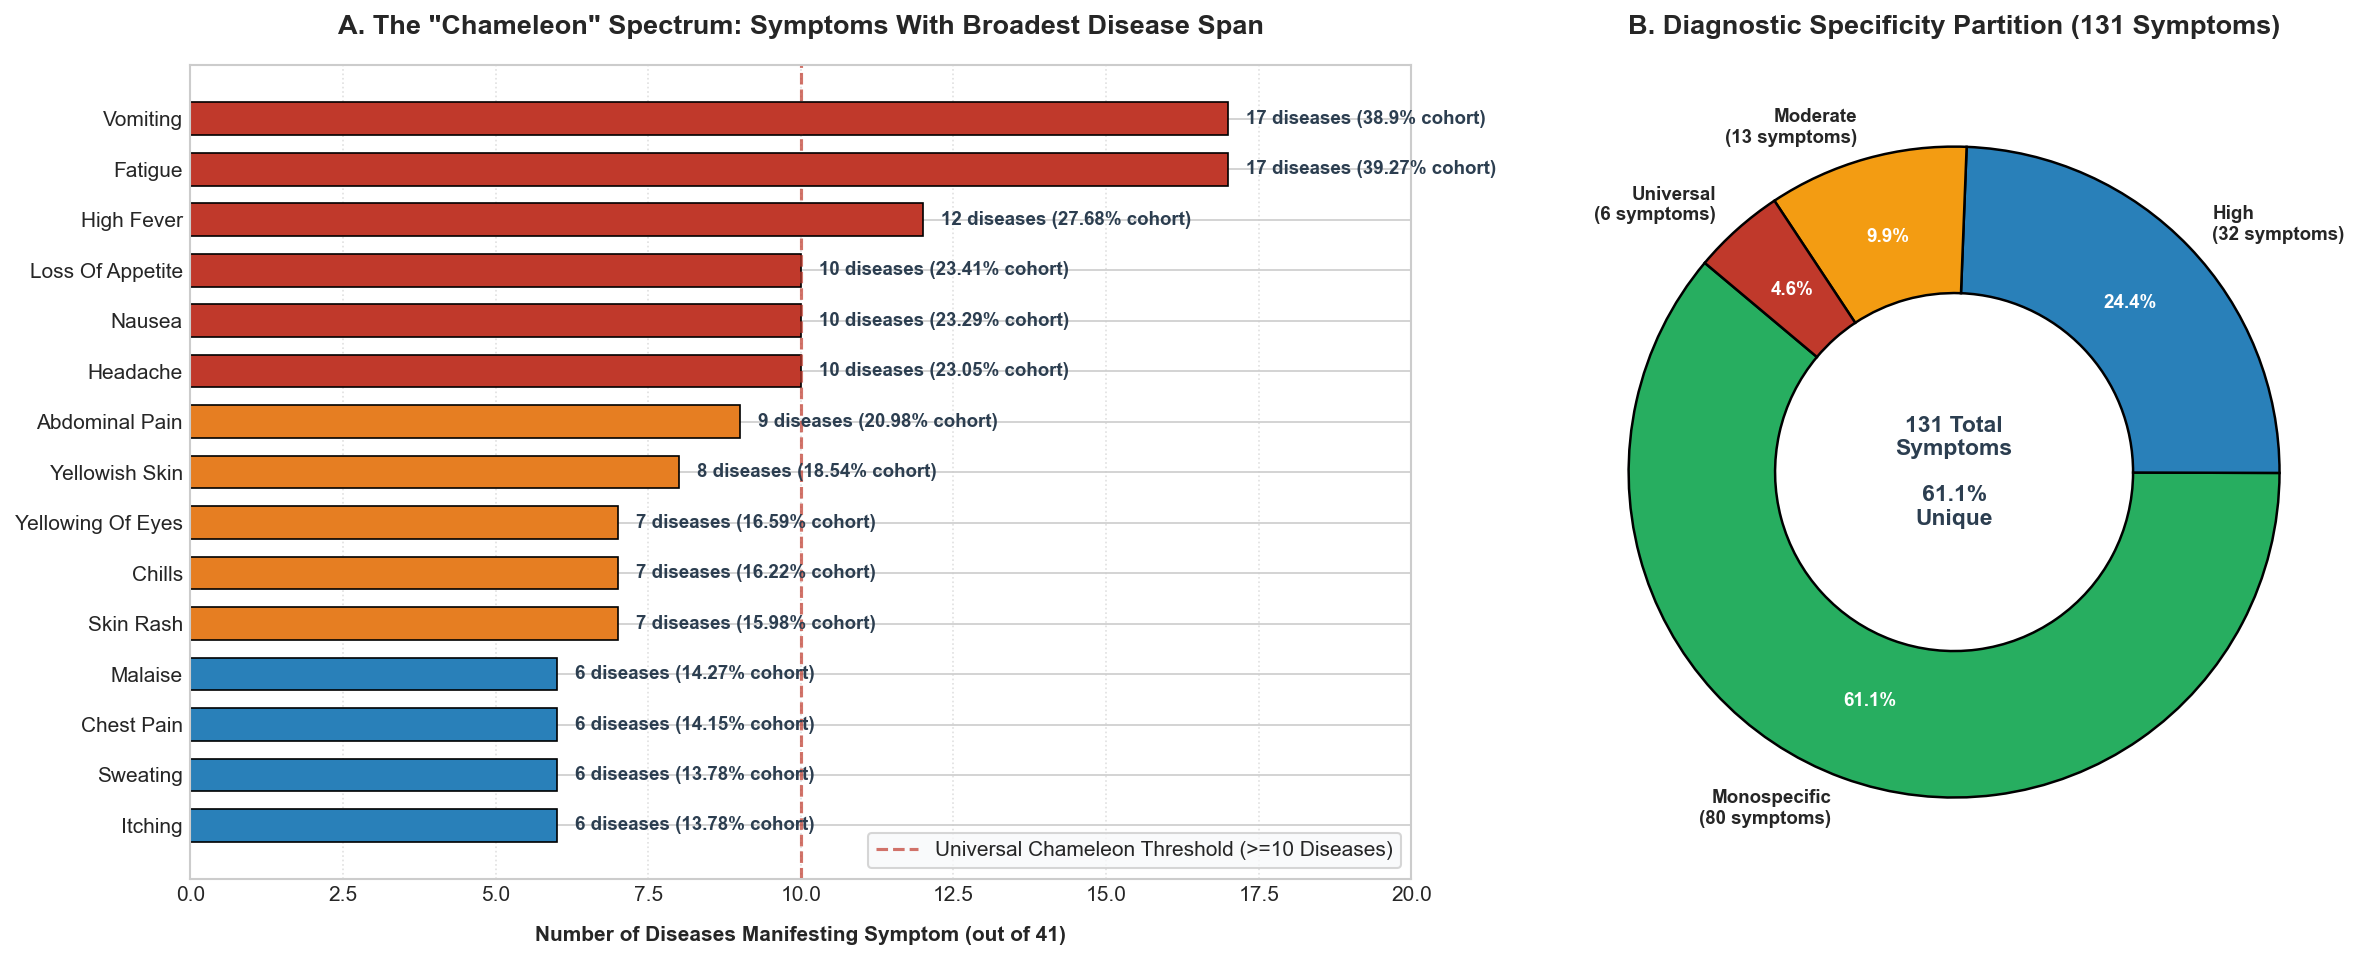

In [4]:
# Visualizing Question 1
df_symptom_metrics = pd.read_csv('data/Symptom_Profile_Metrics.csv')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1.8, 1.2]})

# Panel A: Top 15 Ubiquitous Chameleon Symptoms
top_15_symp = df_symptom_metrics.head(15).sort_values(by='diseases_affected_count', ascending=True)
colors = ['#c0392b' if c >= 10 else '#e67e22' if c >= 7 else '#2980b9' for c in top_15_symp['diseases_affected_count']]

bars = ax1.barh(top_15_symp['symptom'].str.replace('_', ' ').str.title(), 
                top_15_symp['diseases_affected_count'], 
                color=colors, height=0.65, edgecolor='black', linewidth=0.8)

ax1.set_xlabel('Number of Diseases Manifesting Symptom (out of 41)', labelpad=10)
ax1.set_title('A. The "Chameleon" Spectrum: Symptoms With Broadest Disease Span', pad=15)
ax1.set_xlim(0, 20)
ax1.axvline(10, color='#c0392b', linestyle='--', linewidth=1.5, alpha=0.7, label='Universal Chameleon Threshold (>=10 Diseases)')

for bar, prev in zip(bars, top_15_symp['patient_prevalence_pct']):
    width = bar.get_width()
    ax1.text(width + 0.3, bar.get_y() + bar.get_height()/2, 
             f"{int(width)} diseases ({prev}% cohort)", 
             va='center', ha='left', fontsize=9, fontweight='bold', color='#2c3e50')

ax1.legend(loc='lower right', frameon=True, facecolor='#f8f9fa')
ax1.grid(axis='x', linestyle=':', alpha=0.6)

# Panel B: Specificity Spectrum Categorical Distribution
spec_counts = df_symptom_metrics['specificity_class'].value_counts()
spec_order = ['Monospecific (Pathognomonic)', 'High Specificity (Oligospecific)', 
              'Moderate Specificity (Polyspecific)', 'Universal Chameleon (Non-Specific)']
spec_counts = spec_counts.reindex(spec_order)
donut_colors = ['#27ae60', '#2980b9', '#f39c12', '#c0392b']

wedges, texts, autotexts = ax2.pie(
    spec_counts, 
    labels=[f"{c.split(' ')[0]}\n({n} symptoms)" for c, n in zip(spec_order, spec_counts)],
    autopct='%1.1f%%',
    startangle=140,
    colors=donut_colors,
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=1.2),
    pctdistance=0.75,
    textprops={'fontsize': 9, 'fontweight': 'bold'}
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

ax2.set_title('B. Diagnostic Specificity Partition (131 Symptoms)', pad=15)
ax2.text(0, 0, f"131 Total\nSymptoms\n\n61.1%\nUnique", ha='center', va='center', fontsize=11, fontweight='bold', color='#2c3e50')

plt.tight_layout()
plt.show()

## 6. Analytical Question 2: Disease Complexity & Patient Symptom Burden

### Question:
> *How does patient symptom burden (number of co-manifesting symptoms) vary across clinical conditions, and which disease categories represent high-complexity multi-system syndromes?*

### Why this Question Matters (Operational Decision Impact):
Resource allocation in outpatient clinics depends heavily on expected patient evaluation complexity. High-burden diseases require prolonged consultation slots and comprehensive diagnostic panels, whereas low-burden conditions can be directed into fast-track triage streams.

### Design Choices ("Explain Your Choices"):
* **Why this graph?** An ordered horizontal boxplot with overlaid jittered points shows both the central tendency (median/IQR) and discrete patient variations across all 41 diseases.
* **Why this colour?** Six distinct categorical hues encode the hospital clinical domains, visually highlighting domain-level clustering.
* **Why this aggregation?** Row-wise sum of active symptoms per patient encounter, aggregated by Median, IQR, and Range per disease.
* **What should the reader notice?** There is a dramatic 4-fold divergence: Common Cold (17 symptoms), Tuberculosis (16 symptoms), and Dengue (14 symptoms) present with heavy systemic burdens, whereas Heart Attack, Paralysis, and UTI present with strictly 4 symptoms.

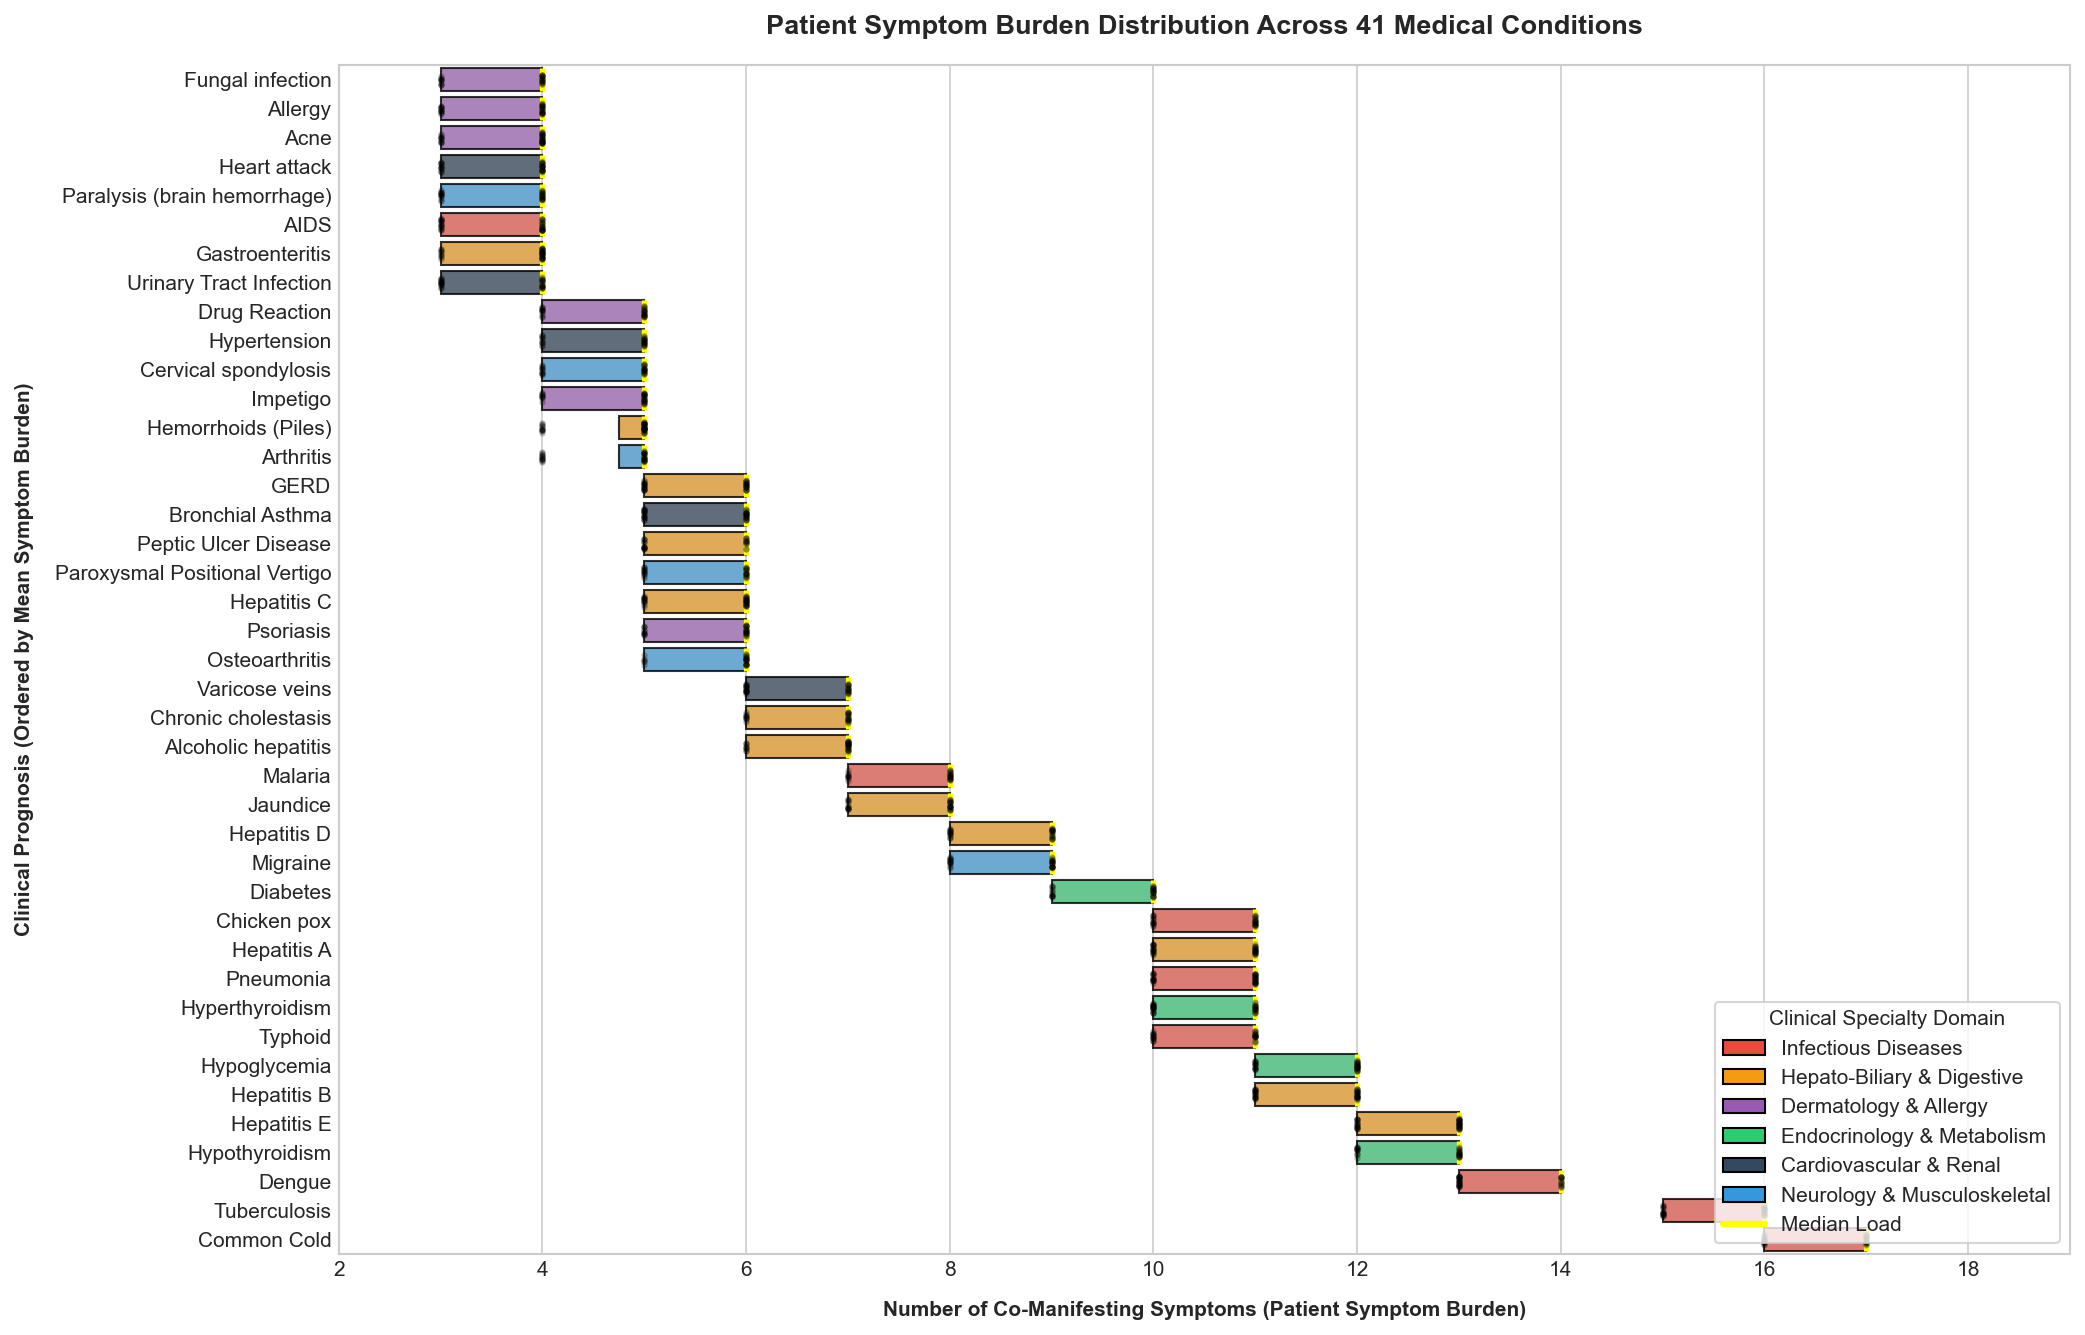

In [5]:
# Visualizing Question 2
df_disease_summary = pd.read_csv('data/Disease_Summary.csv')
order = df_disease_summary.sort_values(by='mean_symptom_load', ascending=True)['prognosis'].tolist()

domain_colors = {
    'Infectious Diseases': '#e74c3c',
    'Hepato-Biliary & Digestive': '#f39c12',
    'Dermatology & Allergy': '#9b59b6',
    'Endocrinology & Metabolism': '#2ecc71',
    'Cardiovascular & Renal': '#34495e',
    'Neurology & Musculoskeletal': '#3498db'
}

palette_list = [domain_colors.get(df_disease_summary.set_index('prognosis').loc[d, 'clinical_domain'], '#95a5a6') for d in order]

fig, ax = plt.subplots(figsize=(14, 9))

sns.boxplot(
    data=df,
    y='prognosis',
    x='symptom_count',
    order=order,
    palette=palette_list,
    fliersize=0,
    boxprops=dict(alpha=0.8, edgecolor='black', linewidth=1),
    medianprops=dict(color='yellow', linewidth=2.5),
    ax=ax
)

sns.stripplot(
    data=df.sample(1500, random_state=42),
    y='prognosis',
    x='symptom_count',
    order=order,
    color='black',
    alpha=0.25,
    size=3,
    jitter=0.2,
    ax=ax
)

ax.set_title('Patient Symptom Burden Distribution Across 41 Medical Conditions', pad=15)
ax.set_xlabel('Number of Co-Manifesting Symptoms (Patient Symptom Burden)', labelpad=10)
ax.set_ylabel('Clinical Prognosis (Ordered by Mean Symptom Burden)', labelpad=10)
ax.set_xlim(2, 19)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, edgecolor='black', label=dom) for dom, c in domain_colors.items()]
legend_elements.append(plt.Line2D([0], [0], color='yellow', lw=3, label='Median Load'))
ax.legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='#ffffff', title='Clinical Specialty Domain')

plt.tight_layout()
plt.show()

## 7. Analytical Question 3: Disease Pairwise Similarity & Diagnostic Ambiguity

### Question:
> *Which disease pairs share severe symptom profile similarity, creating critical operational risks for triage misdirection and diagnostic confusion?*

### Why this Question Matters (Clinical Safety & Error Mitigation):
Conditions with high symptom overlap cannot be safely differentiated by subjective symptom screening alone. Identifying these pairs allows triage systems to insert hard safety rails: automated prompts that trigger mandatory confirmatory lab orders (e.g., viral serology or blood smears) rather than heuristic discharge.

### Design Choices ("Explain Your Choices"):
* **Why this graph?** A 41x41 clustered heatmap shows global overlap topology, paired with a horizontal bar chart highlighting the top 12 highest-risk confusion pairs ($ \ge 0.60 $ similarity).
* **Why this colour?** The `YlOrRd` sequential palette keeps low-similarity pairs subdued in light cream while igniting high-risk overlaps in vivid red.
* **Why this aggregation?** Pairwise Cosine Similarity between 131-dimensional binary symptom vectors.
* **What should the reader notice?**
  1. **Viral Hepatitis Confusion Cluster:** Hepatitis D and E share **83.0%** overlap; Hepatitis D and A share **79.8%** overlap.
  2. **Cross-Domain Respiratory Overlap:** Pneumonia and Tuberculosis share **66.7%** similarity.
  3. **Febrile Systemic Overlap:** Malaria and Typhoid share **63.6%** similarity.

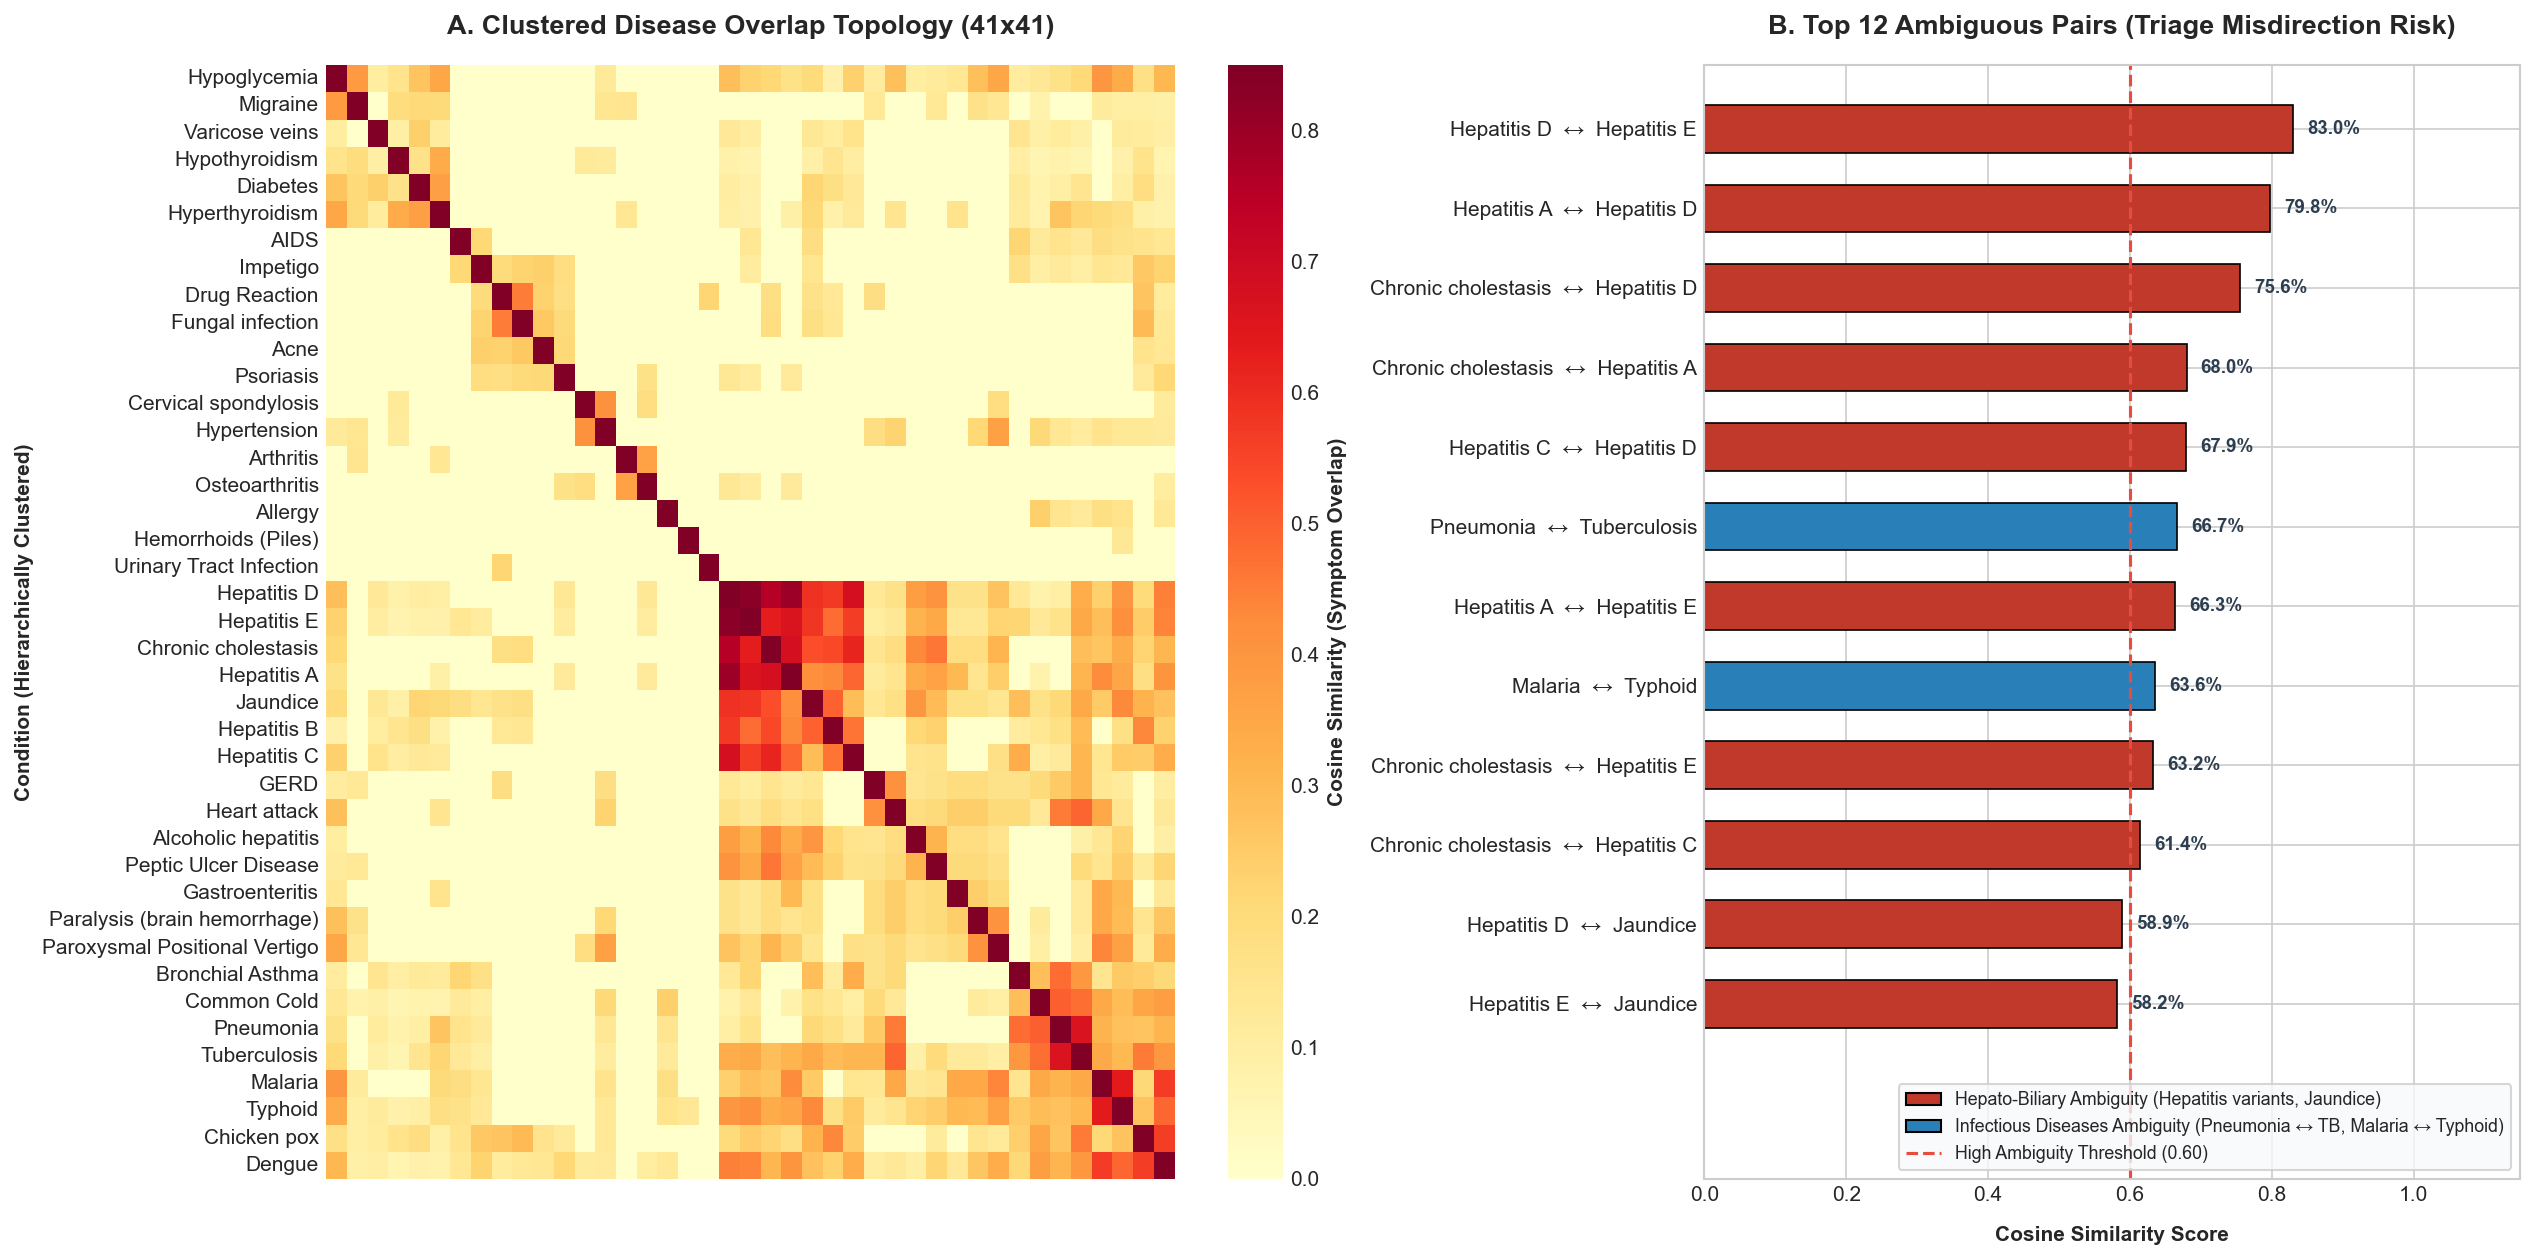

In [6]:
# Visualizing Question 3
df_sim_matrix = pd.read_csv('data/Disease_Similarity_Matrix.csv', index_col=0)
df_pairwise = pd.read_csv('data/Disease_Pairwise_Similarity.csv')

fig = plt.figure(figsize=(17, 8.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1.0])

# Panel A: Clustered Heatmap
ax_heat = fig.add_subplot(gs[0])
dist_condensed = pdist(df_sim_matrix.values, metric='euclidean')
linkage_mat = linkage(dist_condensed, method='ward')
order_idx = leaves_list(linkage_mat)
ordered_diseases = [df_sim_matrix.index[i] for i in order_idx]
clustered_sim = df_sim_matrix.loc[ordered_diseases, ordered_diseases]

sns.heatmap(
    clustered_sim,
    cmap='YlOrRd',
    vmin=0.0,
    vmax=0.85,
    cbar_kws={'label': 'Cosine Similarity (Symptom Overlap)'},
    xticklabels=False,
    yticklabels=True,
    ax=ax_heat
)
ax_heat.set_title('A. Clustered Disease Overlap Topology (41x41)', pad=15)
ax_heat.set_ylabel('Condition (Hierarchically Clustered)')

# Panel B: Top 12 High-Risk Ambiguity Pairs
ax_bar = fig.add_subplot(gs[1])
top_pairs = df_pairwise.head(12).sort_values(by='cosine_similarity', ascending=True)

pair_labels = [f"{r['disease_a']}  ↔  {r['disease_b']}" for _, r in top_pairs.iterrows()]

domain_pair_colors = {
    'Hepato-Biliary & Digestive': '#c0392b',
    'Infectious Diseases': '#2980b9'
}
pair_colors = [domain_pair_colors.get(r['domain_a'], '#7f8c8d') for _, r in top_pairs.iterrows()]

bars = ax_bar.barh(pair_labels, top_pairs['cosine_similarity'], color=pair_colors, height=0.6, edgecolor='black', linewidth=0.8)
ax_bar.set_xlim(0, 1.15)
ax_bar.set_ylim(-2.2, 11.8)
ax_bar.set_xlabel('Cosine Similarity Score', labelpad=10)
ax_bar.set_title('B. Top 12 Ambiguous Pairs (Triage Misdirection Risk)', pad=15)
ax_bar.axvline(0.60, color='#e74c3c', linestyle='--', linewidth=1.5, label='High Ambiguity Threshold (>= 0.60)')

for bar in bars:
    w = bar.get_width()
    ax_bar.text(w + 0.02, bar.get_y() + bar.get_height()/2, f"{w*100:.1f}%", va='center', ha='left', fontsize=9, fontweight='bold', color='#2c3e50')

legend_handles = [
    Patch(facecolor='#c0392b', edgecolor='black', label='Hepato-Biliary Ambiguity (Hepatitis variants, Jaundice)'),
    Patch(facecolor='#2980b9', edgecolor='black', label='Infectious Diseases Ambiguity (Pneumonia ↔ TB, Malaria ↔ Typhoid)'),
    plt.Line2D([0], [0], color='#e74c3c', linestyle='--', lw=1.5, label='High Ambiguity Threshold (0.60)')
]
ax_bar.legend(handles=legend_handles, loc='lower right', frameon=True, facecolor='#f8f9fa', fontsize=8.5)

plt.tight_layout()
plt.show()

## 8. Analytical Question 4: Dataset Structural Imbalance & Synthetic Artifacts

### Question:
> *Where does the dataset exhibit structural imbalance—in disease representation versus symptom rarity—and what synthetic artifacts must healthcare analytics teams correct before model deployment?*

### Why this Question Matters (Data Architecture & Bias Impact):
Machine learning models trained on this benchmark frequently report artificial 100% test accuracy. Uncovering the dual structural imbalances (flat disease quota vs. extreme long-tail Pareto symptom distribution) proves that benchmark performance does not translate directly to real-world healthcare settings.

### Design Choices ("Explain Your Choices"):
* **Why this graph?** A dual-panel juxtaposition contrasting the perfectly uniform disease cohort against a Pareto chart (bar + cumulative percentage curve) of symptom frequencies.
* **Why this colour?** Sky blue for uniform disease bars, slate navy for symptom bars, and alert orange (`#e67e22`) with red dashed lines for the 80% Pareto threshold.
* **Why this aggregation?** Cumulative percentage of total symptom occurrences against descending feature rank.
* **What should the reader notice?**
  1. Exactly 120 cases per disease represents a synthetic distribution completely disconnected from real-world incidence.
  2. Pareto principle in action: just 20 out of 131 symptoms (15.3%) account for 50.7% of all symptom occurrences, and 66 symptoms (50.4%) account for 80.0%. The remaining 65 symptoms represent an extensive sparse tail.
  3. Raw data bug reconciled: raw `fluid_overload` had 0 occurrences due to duplicate header collision with `fluid_overload.1` (114 cases in Alcoholic Hepatitis); reconciled to 114 valid occurrences during audit.

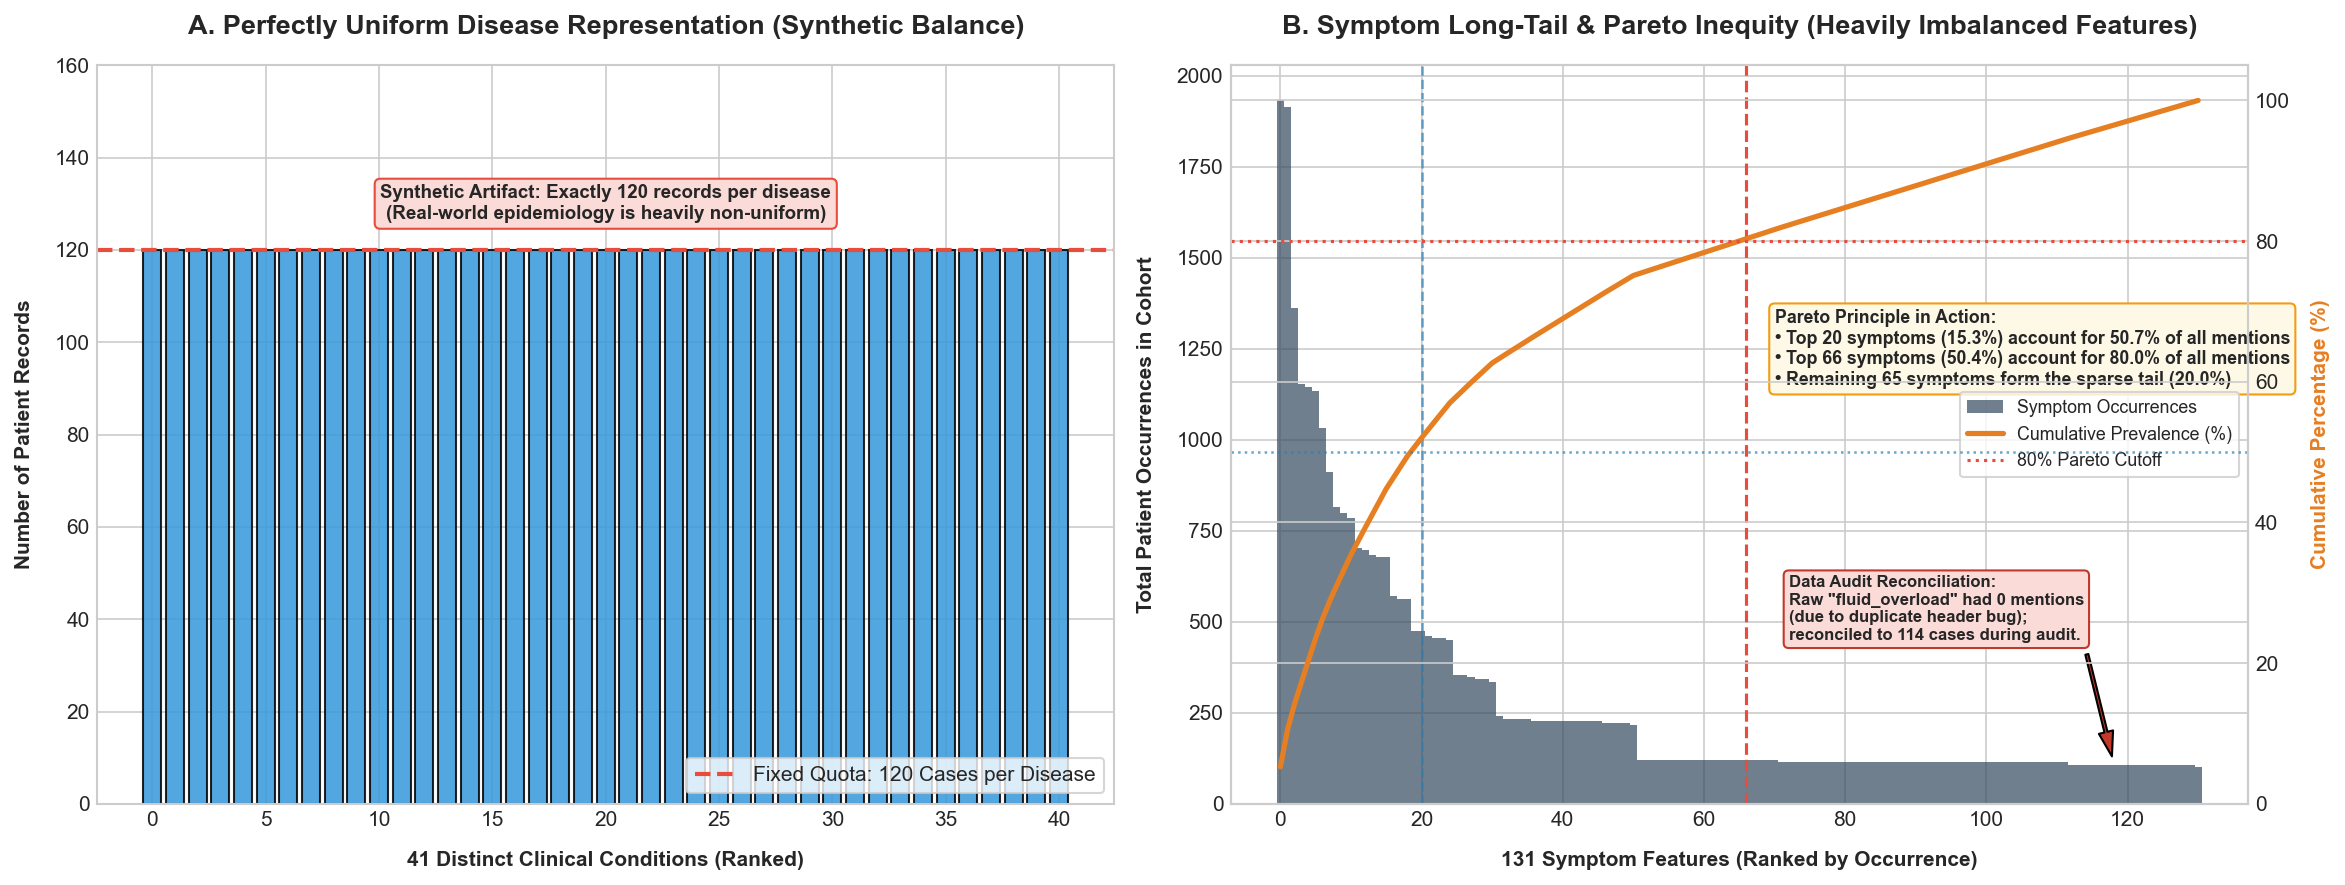

In [7]:
# Visualizing Question 4
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Disease Cohort Distribution
disease_counts = df['prognosis'].value_counts()
ax1.bar(range(len(disease_counts)), disease_counts.values, color='#3498db', edgecolor='black', alpha=0.85, width=0.8)
ax1.set_title('A. Perfectly Uniform Disease Representation (Synthetic Balance)', pad=15)
ax1.set_xlabel('41 Distinct Clinical Conditions (Ranked)', labelpad=10)
ax1.set_ylabel('Number of Patient Records', labelpad=10)
ax1.set_ylim(0, 160)
ax1.axhline(120, color='#e74c3c', linestyle='--', linewidth=2, label='Fixed Quota: 120 Cases per Disease')
ax1.text(20, 130, 'Synthetic Artifact: Exactly 120 records per disease\n(Real-world epidemiology is heavily non-uniform)', 
         ha='center', va='center', bbox=dict(boxstyle='round', facecolor='#fadbd8', edgecolor='#e74c3c'), fontweight='bold', fontsize=9)
ax1.legend(loc='lower right', frameon=True)

# Panel B: Symptom Long-Tail Pareto Distribution
symp_freq_sorted = df_symptom_metrics.sort_values(by='patient_frequency', ascending=False).reset_index(drop=True)
total_mentions = symp_freq_sorted['patient_frequency'].sum()
symp_freq_sorted['cum_pct'] = (symp_freq_sorted['patient_frequency'].cumsum() / total_mentions) * 100

ax2_twin = ax2.twinx()
ax2.bar(range(len(symp_freq_sorted)), symp_freq_sorted['patient_frequency'], color='#34495e', width=1.0, alpha=0.7, label='Symptom Occurrences')
ax2_twin.plot(range(len(symp_freq_sorted)), symp_freq_sorted['cum_pct'], color='#e67e22', linewidth=2.5, label='Cumulative Prevalence (%)')
ax2_twin.axhline(80, color='#e74c3c', linestyle=':', linewidth=1.5, label='80% Pareto Cutoff')
ax2_twin.axhline(50, color='#2980b9', linestyle=':', linewidth=1.2, alpha=0.7)

idx_50 = (symp_freq_sorted['cum_pct'] >= 50).idxmax() + 1   # 20 symptoms
idx_80 = (symp_freq_sorted['cum_pct'] >= 80).idxmax() + 1   # 66 symptoms
ax2.axvline(idx_80, color='#e74c3c', linestyle='--', linewidth=1.5)
ax2.axvline(idx_50, color='#2980b9', linestyle='--', linewidth=1.2, alpha=0.7)

ax2.set_title('B. Symptom Long-Tail & Pareto Inequity (Heavily Imbalanced Features)', pad=15)
ax2.set_xlabel('131 Symptom Features (Ranked by Occurrence)', labelpad=10)
ax2.set_ylabel('Total Patient Occurrences in Cohort', labelpad=10)
ax2_twin.set_ylabel('Cumulative Percentage (%)', labelpad=10, color='#e67e22')
ax2_twin.set_ylim(0, 105)

ax2.text(idx_80 + 4, 1150, 
         f'Pareto Principle in Action:\n• Top {idx_50} symptoms (15.3%) account for 50.7% of all mentions\n• Top {idx_80} symptoms (50.4%) account for 80.0% of all mentions\n• Remaining {131-idx_80} symptoms form the sparse tail (20.0%)',
         bbox=dict(boxstyle='round', facecolor='#fef9e7', edgecolor='#f39c12'), fontweight='bold', fontsize=8.5)

ax2.annotate('Data Audit Reconciliation:\nRaw "fluid_overload" had 0 mentions\n(due to duplicate header bug);\nreconciled to 114 cases during audit.',
             xy=(118, 114), xytext=(72, 450),
             arrowprops=dict(facecolor='#c0392b', shrink=0.05, width=1.5, headwidth=7),
             bbox=dict(boxstyle='round', facecolor='#fadbd8', edgecolor='#c0392b'), fontweight='bold', fontsize=8)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='center right', frameon=True, facecolor='#ffffff', fontsize=8.5)

plt.tight_layout()
plt.show()

## 9. Analytical Question 5: Symptom Co-occurrence & Syndromic Archetypes

### Question:
> *What functional symptom clusters co-occur most strongly in patient presentations, and how can clinical intake questionnaires be modularized into dynamic triage branches?*

### Why this Question Matters (Clinical Workflow Optimization):
Instead of administering all 131 questions linearly, EHR systems can group questions into modular syndromic bundles. When a lead symptom is checked, its tightly coupled companions are automatically revealed, shortening intake duration.

### Design Choices ("Explain Your Choices"):
* **Why this graph?** A masked correlation heatmap of the top 22 most prevalent symptoms isolates significant positive syndromic couplings along the diagonal.
* **Why this colour?** The diverging `icefire` palette centers at zero correlation, muting uncoupled pairs while highlighting strong clinical synergies in warm amber and deep red.
* **Why this aggregation?** Pearson correlation coefficient computed over all 4,920 patient encounters.
* **What should the reader notice?**
  1. **Hepato-Biliary Syndrome:** Yellowish skin, yellowing of eyes, dark urine, and abdominal pain exhibit powerful correlations ($r = 0.53$ to $0.73$).
  2. **Systemic Febrile Syndrome:** High fever, chills, headache, and malaise co-occur consistently ($r = 0.24$ to $0.54$).

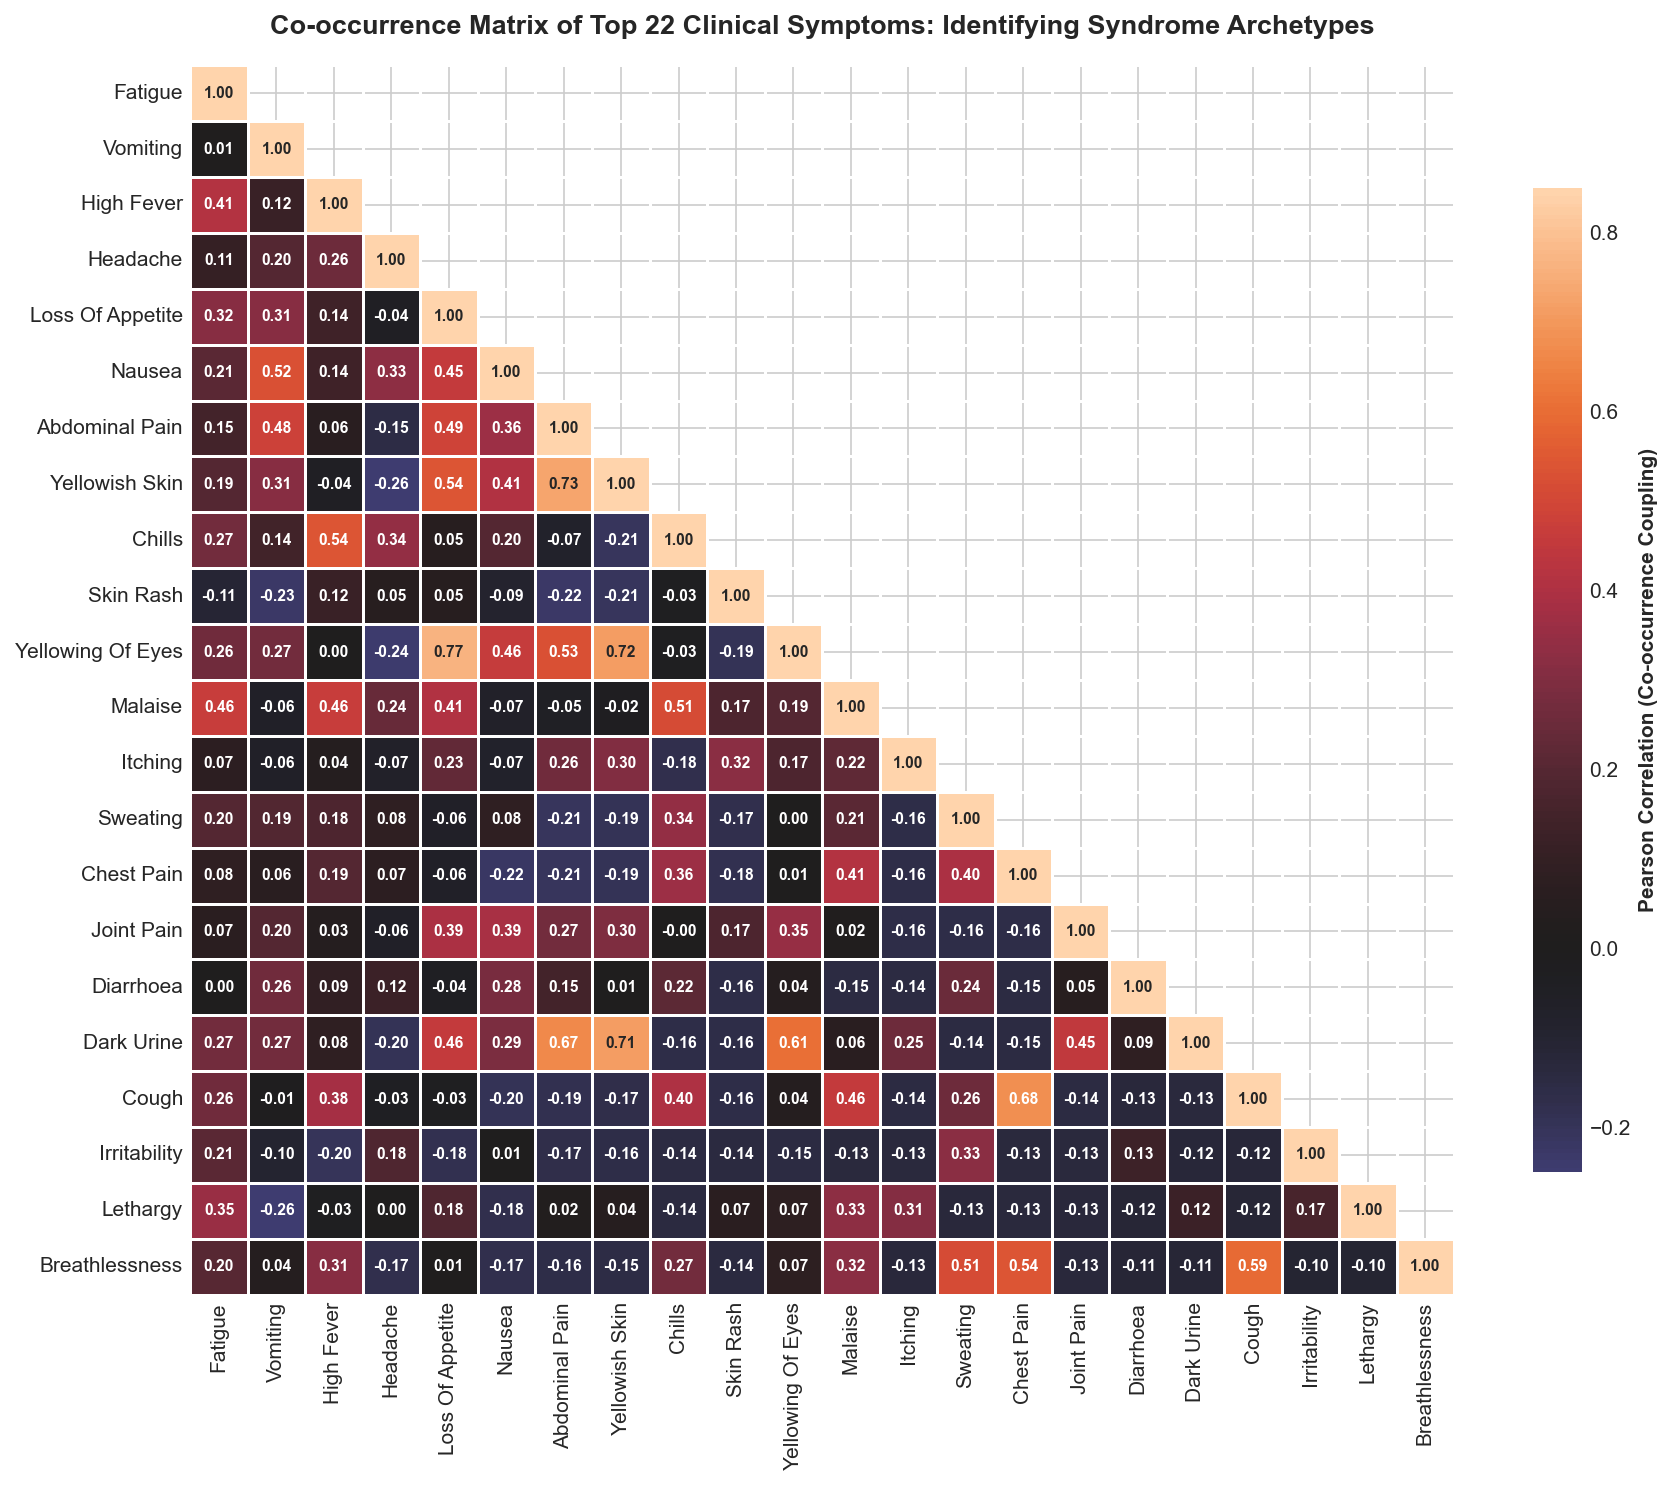

In [8]:
# Visualizing Question 5
top_symps = df_symptom_metrics.head(22)['symptom'].tolist()

corr_matrix = df[top_symps].corr()
corr_matrix.columns = [c.replace('_', ' ').title() for c in top_symps]
corr_matrix.index = [c.replace('_', ' ').title() for c in top_symps]

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='icefire',
    center=0,
    vmin=-0.25,
    vmax=0.85,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 7.5, 'weight': 'bold'},
    cbar_kws={'label': 'Pearson Correlation (Co-occurrence Coupling)', 'shrink': 0.8},
    linewidths=0.5,
    linecolor='white',
    ax=ax
)

ax.set_title('Co-occurrence Matrix of Top 22 Clinical Symptoms: Identifying Syndrome Archetypes', pad=15)
plt.tight_layout()
plt.show()

## 10. Tableau Pipeline & Data Export Verification

To build high-performance dashboards in Tableau without dragging across 131 individual binary columns, we created specialized tidy tables:
* `data/Training_Cleaned.csv` — Full cleaned wide matrix.
* `data/Disease_Symptoms_Long.csv` — Unpivoted long-format dataset ($36,648$ active records).
* `data/Symptom_Profile_Metrics.csv` — Symptom ubiquity and specificity metrics.
* `data/Disease_Pairwise_Similarity.csv` — Pairwise cosine similarities ($820$ pairs).
* `data/Disease_Summary.csv` — Disease complexity and symptom load metrics.

In [9]:
# Verify export file presence and sizes
export_files = [
    'data/Training_Cleaned.csv',
    'data/Disease_Symptoms_Long.csv',
    'data/Symptom_Profile_Metrics.csv',
    'data/Disease_Pairwise_Similarity.csv',
    'data/Disease_Summary.csv'
]

print("Tableau Data Exports Verification:")
for f in export_files:
    if os.path.exists(f):
        size_kb = os.path.getsize(f) / 1024
        df_temp = pd.read_csv(f)
        print(f"  ✓ {f:<35} | Size: {size_kb:>7.1f} KB | Rows: {len(df_temp):>6} | Cols: {len(df_temp.columns):>2}")

Tableau Data Exports Verification:
  ✓ data/Training_Cleaned.csv           | Size:  1503.4 KB | Rows:   4920 | Cols: 135


  ✓ data/Disease_Symptoms_Long.csv      | Size:  3591.5 KB | Rows:  36648 | Cols:  8
  ✓ data/Symptom_Profile_Metrics.csv    | Size:    11.9 KB | Rows:    131 | Cols:  8
  ✓ data/Disease_Pairwise_Similarity.csv | Size:    85.2 KB | Rows:    820 | Cols:  7
  ✓ data/Disease_Summary.csv            | Size:     3.5 KB | Rows:     41 | Cols: 11


## 11. Synthesis: Strategic Decisions & Triage Recommendations

### Key Takeaways for Clinical Informatics Leaders:
1. **Implement Dynamic Branching Triage:** Replace the 131-item static questionnaire with a 2-stage protocol. Screen the top 10 systemic chameleon symptoms first, then dynamically trigger the pathognomonic clusters identified in Q1.
2. **Institute Automated Lab Reflex Triggers:** For disease pairs with cosine similarity $\ge 0.60$ (such as Hepatitis D vs. E and Malaria vs. Typhoid), configure the EHR to mandate immediate confirmatory diagnostic tests rather than relying on clinical intuition.
3. **Calibrate for Real-World Disease Priors:** Models trained on this synthetic dataset must be recalibrated with real-world epidemiological Bayesian priors before deployment to avoid severe false positive rates.

---
*Report and Analysis Generated for Course 23CSE353 - Data Visualization Case Study.*